# Adam parameter sweep: isotropic local statistical efficiency

This companion to `demo_adam_small_denominators.ipynb` sweeps both momentum
parameters for the same isotropic, scalar regression experiments. The objective
is stationary excess risk at **matched local restoring drift**, in the
small-learning-rate limit. It is not a finite-time training optimum.

We compute the manuscript's **shared-history long-run covariance**, not the
variance of a single update. General beta2 values use a small, seeded Monte Carlo
calculation with analytic Gaussian integration by parts for the drift. The
beta2=0 column is replaced by its deterministic one-dimensional quadrature.

The default is an exploratory 8 by 8 grid, 768 independent replicas, and fixed
positive stability. No parameter trajectories or D-dimensional arrays are
simulated. Monte Carlo standard errors and a small independent refinement of the
best grid point are displayed. A grid minimum is not a certified global optimum.

## Models, with the gradient written explicitly
$$f(\zeta,q)=q-\zeta$$
for ordinary Gaussian regression, and
$$f((\omega,\zeta),q)=\omega(q-\zeta),\qquad
\omega\sim\mathrm{Bernoulli}(p)$$
for the inactive-gradient experiments. In both cases
$F=\omega(q-\zeta)^2/2$, with omega identically one for ordinary regression.
The target is zero and K=I. Noise and data are independent across samples.

The defaults show all three variants: Gaussian noise, a 10% chance of zero
gradient, and that same gate with rare large label errors. Select fewer names
below for a faster run. All beta parameters are fixed independently of dimension.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.integrate import quad_vec
from scipy.special import k0


def f_gaussian(noise, q):
    return q - noise

def f_gated(noise, q):
    omega, zeta = noise
    return omega * (q - zeta)

MODELS = {
    'Gaussian': dict(p=1.0, weights=np.array([1.0]), scales=np.array([1.0])),
    'Gated Gaussian': dict(p=0.9, weights=np.array([1.0]), scales=np.array([1.0])),
    'Gated outliers': dict(p=0.9, weights=np.array([0.99, 0.01]), scales=np.array([1.0, 100.0])),
}
model_names = list(MODELS)
beta1_grid = np.array([0., .1, .25, .5, .7, .85, .93, .97])
beta2_grid = np.array([0., .1, .25, .5, .7, .85, .93, .97])
eps = 1e-3
replicas = 768
seed = 2026
history_tol = 1e-3
refinement_replicas = 1536
assert eps > 0 and replicas >= 2
assert np.all((beta1_grid >= 0) & (beta1_grid < 1))
assert np.all((beta2_grid >= 0) & (beta2_grid < 1))
assert np.all(np.diff(beta1_grid) > 0) and np.all(np.diff(beta2_grid) > 0)

## Coefficients and objective
Write $V=\mathbb E\zeta^2$. The local energy equation is
$$\dot b=-2\eta c b+\eta^2s+O(\eta b^2+\eta^2b).$$
SGD has restoring coefficient p. Giving SGD learning rate h and Adam learning
rate $hp/c$ matches the leading local drift. The risk ratio is
$$J(\beta_1,\beta_2)=\frac{p\,s}{V c^2}.$$
SGD has J=1. We also display the true signSGD reference
$J_{\rm sign}=\pi/[8g_\zeta(0)^2V]$, with sign(0)=0 on inactive samples.

At the optimum let $g_t=-\omega_t\zeta_t\xi_t$ and
$$v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,\qquad G_t=\sqrt{v_t+\epsilon}.$$
Conditional on the Gaussian mixture component j, integration by parts gives
$$c=\mathbb E\left[\frac{(1-\beta_1)\sum_{\ell\ge0}
\beta_1^\ell g_{-\ell}^2/\sigma_{j(-\ell)}^2}{G_0}\right].$$
This nonnegative estimator avoids subtracting nearly equal derivative terms.
For covariance we use
$$s=\mathbb E A_0^2,\qquad
A_0=(1-\beta_1)g_0\sum_{\ell\ge0}\frac{\beta_1^\ell}{G_\ell}.$$
Every future denominator in this expression includes the contribution of sample
zero and the same intervening samples.

We stratify the gate and noise-mixture component of sample zero, so rare large
errors are represented even with a small replica count. Other history samples
are drawn from the original mixture. Common histories are reused across the
grid. Each replica is independent of the others.

In [2]:
def history_lengths(b1, b2, model, eps, tol):
    Vg = model['p']*np.sum(model['weights']*model['scales']**2)
    def length(beta, target):
        if beta == 0 or target >= 1:
            return 1
        return max(1, int(np.ceil(np.log(target)/np.log(beta))))
    # The omitted stationary variance has expectation <= eps*tol.
    burn_v = length(float(np.max(b2)), eps*tol/max(Vg, 1e-15))
    burn_c = length(float(np.max(b1)), tol*np.sqrt(eps)/max(model['p'], 1e-15))
    # Exact stationary-history tail bound: ||A0-A0,L||_2 <= sqrt(Vg/eps)*beta1**L.
    future = length(float(np.max(b1)), tol*np.sqrt(eps/max(Vg, 1e-15)))
    burn = max(burn_v, burn_c)
    if max(burn, future) > 5000:
        raise ValueError('History exceeds the lightweight budget. Reduce the largest beta or relax history_tol.')
    return burn, future


def draw_g2(rng, n, model):
    active = rng.random(n) < model['p']
    component = rng.choice(len(model['weights']), n, p=model['weights'])
    sigma = model['scales'][component]
    z, xi = rng.standard_normal((2, n))
    score = active*(z*xi)**2
    return sigma**2*score, score


def estimate_grid(b1, b2, model, eps, n, seed, tol):
    b1, b2 = np.asarray(b1), np.asarray(b2)
    rng = np.random.default_rng(seed)
    burn, future = history_lengths(b1, b2, model, eps, tol)
    v_past = np.zeros((len(b2), n))
    score_past = np.zeros((len(b1), n))
    for _ in range(burn):
        g2, score = draw_g2(rng, n, model)
        v_past = b2[:,None]*v_past + (1-b2[:,None])*g2
        score_past = b1[:,None]*score_past + (1-b1[:,None])*score
    # Arrays are ordered [beta1, beta2, independent replica].
    c_samples = np.zeros((len(b1), len(b2), n))
    s_samples = np.zeros_like(c_samples)
    strata = []
    if model['p'] < 1:
        strata.append((1-model['p'], 0.0))
    strata += [(model['p']*w, sigma) for w, sigma in zip(model['weights'], model['scales']) if w > 0]
    for mass, sigma in strata:
        z, xi = rng.standard_normal((2, n))
        score0 = (z*xi)**2 if sigma > 0 else np.zeros(n)
        g02 = sigma**2*score0
        v = b2[:,None]*v_past + (1-b2[:,None])*g02
        score0_ema = b1[:,None]*score_past + (1-b1[:,None])*score0
        invG = 1/np.sqrt(v+eps)
        c_samples += mass*score0_ema[:,None,:]*invG[None,:,:]
        sums = np.broadcast_to(invG, (len(b1), len(b2), n)).copy()
        powers = np.ones(len(b1))
        for _ in range(1, future):
            g2, _ = draw_g2(rng, n, model)
            v = b2[:,None]*v + (1-b2[:,None])*g2
            powers *= b1
            sums += powers[:,None,None]/np.sqrt(v[None,:,:]+eps)
        s_samples += mass*(1-b1[:,None,None])**2*g02[None,None,:]*sums**2
    c, s = c_samples.mean(axis=-1), s_samples.mean(axis=-1)
    V = np.sum(model['weights']*model['scales']**2)
    J = model['p']*s/(V*c*c)
    # Paired delta-method SE: includes covariance between c and s estimators.
    influence = J[:,:,None]*(s_samples/s[:,:,None]-2*c_samples/c[:,:,None]+1)
    se = influence.std(axis=-1, ddof=1)/np.sqrt(n)
    return dict(c=c, s=s, J=J, se=se, burn=burn, future=future)

## Exact beta2=0 boundary
Small denominators can make naive Monte Carlo particularly unreliable on this
boundary. We use its exact history reduction and deterministic Gaussian-product
quadrature instead. Standard errors there are recorded as zero to denote
quadrature, not proof of zero numerical error.

In [3]:
_cache = {}
def active_moments(eps, sigma):
    key = (float(eps), float(sigma))
    if key not in _cache:
        def integrand(u):
            z = np.exp(u); g2 = (sigma*z)**2; den = g2+eps
            return (2/np.pi)*k0(z)*z*np.array([
                np.sqrt(eps/den), eps/den, g2/(sigma*np.sqrt(den)), g2/den])
        val, _ = quad_vec(integrand, -50, 4, epsabs=2e-9, epsrel=2e-9)
        _cache[key] = val*np.array([1/np.sqrt(eps), 1/eps, sigma, 1])
    return _cache[key]


def exact_boundary(betas, model, eps):
    p, w, sig = model['p'], model['weights'], model['scales']
    active = np.array([active_moments(eps, x) for x in sig])
    mu, nu, A, D0 = p*(w @ active)
    mu += (1-p)/np.sqrt(eps); nu += (1-p)/eps
    C = p*np.sum(w*active[:,2]/sig**2)
    V = np.sum(w*sig**2)
    beta = np.asarray(betas)
    c = (1-beta)*C+beta*p*mu
    s = ((1-beta)**2*D0+2*beta*(1-beta)*mu*A
         +beta**2*p*V*(mu**2+(1-beta)/(1+beta)*max(nu-mu**2, 0)))
    return c, s, p*s/(V*c*c)


def sign_reference(model):
    V = np.sum(model['weights']*model['scales']**2)
    density0 = np.sum(model['weights']/model['scales'])/np.sqrt(2*np.pi)
    return np.pi/(8*density0**2*V)

results = {}
for j, name in enumerate(model_names):
    model = MODELS[name]
    result = estimate_grid(beta1_grid, beta2_grid, model, eps, replicas, seed+j, history_tol)
    if 0.0 in beta2_grid:
        col = np.flatnonzero(beta2_grid == 0)[0]
        c, s, J = exact_boundary(beta1_grid, model, eps)
        rel = np.max(np.abs(result['J'][:,col]-J)/J)
        print(f'{name}: exploratory MC boundary discrepancy {rel:.1%}; using quadrature boundary.')
        result['c'][:,col], result['s'][:,col], result['J'][:,col] = c, s, J
        result['se'][:,col] = 0
    results[name] = result
    print(f"  burn-in={result['burn']}, future length={result['future']}, replicas={replicas}")

Gaussian: exploratory MC boundary discrepancy 20.0%; using quadrature boundary.
  burn-in=454, future length=341, replicas=768
Gated Gaussian: exploratory MC boundary discrepancy 22.2%; using quadrature boundary.
  burn-in=451, future length=339, replicas=768
Gated outliers: exploratory MC boundary discrepancy 9.5%; using quadrature boundary.
  burn-in=602, future length=415, replicas=768


## Heatmaps and candidate grid minima
Color is log10 J; negative values improve on SGD and positive values are worse.
The dashed curve is beta1=sqrt(beta2), **not a constraint**. Crosses mark cells
with relative Monte Carlo SE above 30%; even unmarked estimates may have
unseen-tail or history bias. The separate uncertainty plot makes this visible.
The star denotes the smallest point estimate, and is only a candidate optimum.

The burn-in and tail rules control omitted input scales. They are not certified
bounds on the nonlinear objective's total bias. The targeted refinement below
uses a new seed, more replicas, and longer histories.

Candidate grid minima; uncertainty is one estimated standard error:
Gaussian: beta1=0.97, beta2=0.5, J=0.8812 +/- 0.092; SGD=1; signSGD=2.467
Gated Gaussian: beta1=0.97, beta2=0.1, J=0.9219 +/- 0.12; SGD=1; signSGD=2.467
Gated outliers: beta1=0, beta2=0.7, J=0.01367 +/- 0.0012; SGD=1; signSGD=0.02492


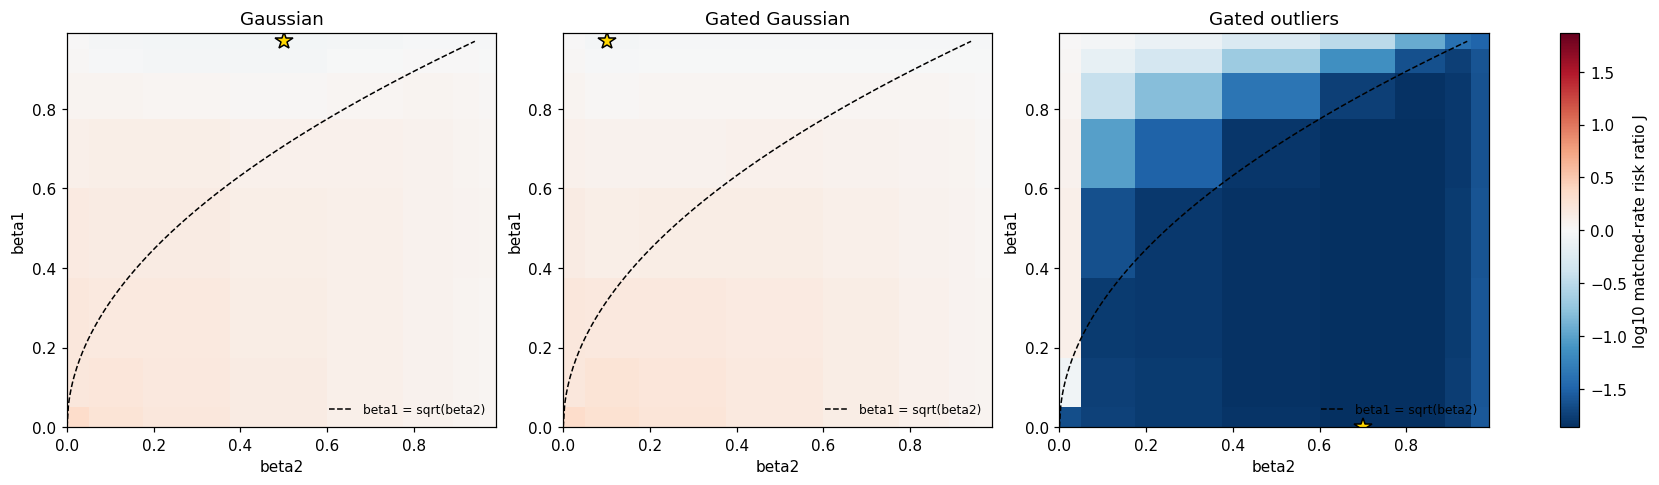

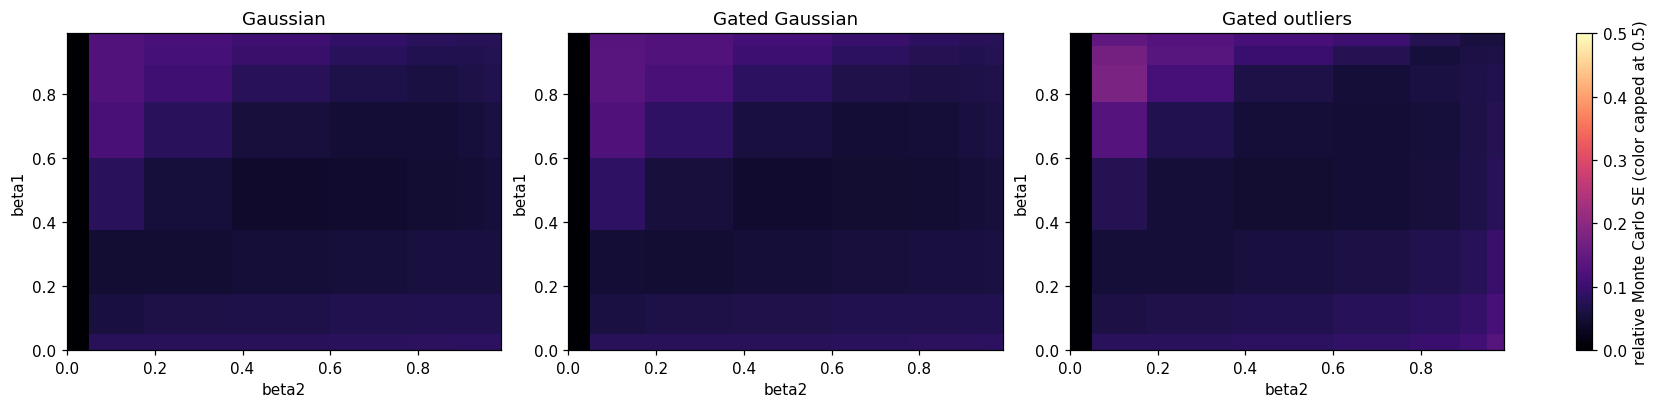

In [4]:
def edges(grid):
    if len(grid) < 2:
        raise ValueError('Use at least two grid points for each heatmap axis.')
    return np.r_[max(0, grid[0]-(grid[1]-grid[0])/2),
                 (grid[:-1]+grid[1:])/2, min(1, grid[-1]+(grid[-1]-grid[-2])/2)]

values = np.concatenate([np.log10(results[n]['J']).ravel() for n in model_names])
scale = max(0.1, np.max(np.abs(values)))
fig, axes = plt.subplots(1, len(model_names), figsize=(5*len(model_names), 4.3), squeeze=False,
                         constrained_layout=True)
candidates = {}
for ax, name in zip(axes[0], model_names):
    r = results[name]
    mesh = ax.pcolormesh(edges(beta2_grid), edges(beta1_grid), np.log10(r['J']),
                         cmap='RdBu_r', vmin=-scale, vmax=scale, shading='flat')
    x = np.linspace(beta2_grid[0], beta2_grid[-1], 300)
    y = np.sqrt(x); keep = (y >= beta1_grid[0]) & (y <= beta1_grid[-1])
    ax.plot(x[keep], y[keep], 'k--', lw=1, label='beta1 = sqrt(beta2)')
    i, j = np.unravel_index(np.argmin(r['J']), r['J'].shape)
    candidates[name] = (i, j)
    ax.plot(beta2_grid[j], beta1_grid[i], '*', color='gold', mec='k', ms=12)
    ii, jj = np.where(r['se']/r['J'] > 0.30)
    ax.scatter(beta2_grid[jj], beta1_grid[ii], marker='x', color='k', s=15)
    ax.set(xlabel='beta2', ylabel='beta1', title=name)
    ax.legend(frameon=False, fontsize=8, loc='lower right')
fig.colorbar(mesh, ax=axes.ravel().tolist(), label='log10 matched-rate risk ratio J')
plt.show()

fig, axes = plt.subplots(1, len(model_names), figsize=(5*len(model_names), 3.6), squeeze=False,
                         constrained_layout=True)
for ax, name in zip(axes[0], model_names):
    r = results[name]
    mesh = ax.pcolormesh(edges(beta2_grid), edges(beta1_grid), r['se']/r['J'],
                         cmap='magma', vmin=0, vmax=0.5, shading='flat')
    ax.set(xlabel='beta2', ylabel='beta1', title=name)
fig.colorbar(mesh, ax=axes.ravel().tolist(), label='relative Monte Carlo SE (color capped at 0.5)')
plt.show()

print('Candidate grid minima; uncertainty is one estimated standard error:')
for name, (i, j) in candidates.items():
    r = results[name]
    print(f"{name}: beta1={beta1_grid[i]:.3g}, beta2={beta2_grid[j]:.3g}, "
          f"J={r['J'][i,j]:.4g} +/- {r['se'][i,j]:.2g}; "
          f"SGD=1; signSGD={sign_reference(MODELS[name]):.4g}")

## Small independent check of the selected points
This checks one candidate per model, not the entire grid. It does not remove
selection bias or establish that neighboring or unsampled parameters are worse.
If uncertainty is large, increase replicas for a focused subgrid rather than
running a much larger full sweep. Endpoints beta1=1 and beta2=1 are excluded.

In [5]:
for k, (name, (i, j)) in enumerate(candidates.items()):
    b1, b2 = beta1_grid[i], beta2_grid[j]
    if b2 == 0:
        _, _, J = exact_boundary(np.array([b1]), MODELS[name], eps)
        print(f'{name}: selected boundary is quadrature-based, J={J[0]:.5g}.')
        continue
    refined = estimate_grid(np.array([b1]), np.array([b2]), MODELS[name], eps,
                            refinement_replicas, seed+100+k, history_tol/10)
    print(f"{name}: independent refinement J={refined['J'][0,0]:.5g} "
          f"+/- {refined['se'][0,0]:.2g}; burn={refined['burn']}, future={refined['future']}")

# Light structural checks; Monte Carlo agreement is reported rather than asserted.
for r in results.values():
    assert np.all(np.isfinite(r['J'])) and np.all(r['c'] > 0) and np.all(r['s'] > 0)
    assert np.all(np.isfinite(r['se'])) and np.all(r['se'] >= 0)
print('Structural checks passed. No optimizer trajectories or large tests were run.')

Gaussian: independent refinement J=0.93467 +/- 0.07; burn=416, future=416
Gated Gaussian: independent refinement J=1.0167 +/- 0.1; burn=413, future=415
Gated outliers: independent refinement J=0.012421 +/- 0.00084; burn=58, future=1
Structural checks passed. No optimizer trajectories or large tests were run.


To explore another stability value, change `eps` and rerun. Very small epsilon
can produce rare-event dominated estimates even when their estimated standard
errors look small. The exact beta2=0 column remains useful as an anchor.

The fixed-history and fixed-beta stationary approximation does not measure
startup costs. A candidate close to one is not evidence that beta=1 is valid or
optimal. The notebook searches a finite grid at one stability value; it does
not solve the continuous first-order conditions or claim a global optimum.